# Introduction to AI — Common Errors and Debugging

**Notebook status:** execution below is saved from a local run. Python 3.13.14; deterministic, synthetic examples; no API credentials or external services.

## Section A — Introduction

Diagnose invalid model state, bad inputs, and misleading evaluation. Robust systems fail clearly instead of returning invented predictions.

**Prerequisites:** Python 3.11+, basic values and function calls. Install notebook support with `python -m pip install -e ".[notebooks]"`. **Objectives:** trace the code, explain its output, identify limitations, and suggest a real-world safety boundary. Full theory: [lesson notes](../lessons/01_introduction_to_artificial_intelligence.md).

In [1]:
import sys
import matplotlib

print(f"Python {sys.version.split()[0]} | matplotlib {matplotlib.__version__}")

Python 3.13.14 | matplotlib 3.10.8


This environment cell records the actual interpreter and plotting-library versions used for this notebook execution. Minimum compatible dependency versions are documented in the course `pyproject.toml`.

## Section B — Beginner explanation

An exception signals an operation could not proceed. Validation checks assumptions before use. The examples catch expected errors so the notebook has no unhandled failure.

The code cells are runnable Python. Explanations before and after each cell distinguish the expected behavior from the actual output saved by this execution.

## Section C — First Python example

Read the inputs and operations before running. The output below is captured from actual execution.

In [2]:
def safe_predict(value, centers):
    if not centers:
        raise ValueError("model has no fitted centroids")
    return min(centers, key=lambda label: abs(value-centers[label]))

centers = {"normal": 11.0, "review": 85.0}
print("valid prediction:", safe_predict(70.0, centers))

valid prediction: review


**Line-by-line walkthrough:** The function takes a value and centroid mapping, checks model state, calculates absolute distances, and returns the nearest label. The final call uses a valid toy model.

The output immediately above is actual saved execution output. It occurs because the code uses the displayed deterministic input.

## Section D — Intermediate examples

This example adds a more realistic data structure or evaluation step. Inputs are documented in the code.

In [3]:
for value, model in [(70, centers), (3, {}), (None, centers)]:
    try:
        print("prediction:", safe_predict(value, model))
    except (ValueError, TypeError) as error:
        print(f"rejected {value!r}: {type(error).__name__}: {error}")

prediction: review
rejected 3: ValueError: model has no fitted centroids
rejected None: TypeError: unsupported operand type(s) for -: 'NoneType' and 'float'


This cell's output is the result of the displayed computation. New Python operations are explained in the code and can be inspected interactively.

## Section E — Advanced examples

This example adds an edge case, metric, or validation concern. Consider both computational behavior and decision consequences.

In [4]:
import math
def robust_predict(value, model):
    if not isinstance(value, (int, float)) or not math.isfinite(value):
        raise ValueError("value must be finite numeric data")
    if not model or any(not math.isfinite(center) for center in model.values()):
        raise ValueError("model must contain finite fitted centroids")
    return min(model, key=lambda label: abs(value-model[label]))

for value in (70.0, float("nan")):
    try:
        print("result:", robust_predict(value, centers))
    except ValueError as error:
        print("validation:", error)

result: review
validation: value must be finite numeric data


Interpret each result in the context of the toy data; do not generalize the score to real deployments.

## Section F — Real-world applications

Example application: synthetic network engineering telemetry and read-only triage. The same principles apply to AI, data science, cloud monitoring, automation, and production software.

In [5]:
training = [(10, 0), (12, 0), (80, 1), (90, 1)]
print("training examples:", len(training))
print("Correct interpretation: fitting data are not an independent future-performance estimate.")

training examples: 4
Correct interpretation: fitting data are not an independent future-performance estimate.


No live network is contacted. Any production system needs data provenance, permissions, observability, human review, and a rollback/disable plan.

## Section G — Visualization

The chart below is rendered and embedded in this notebook's saved outputs. It uses the small synthetic demonstration data.

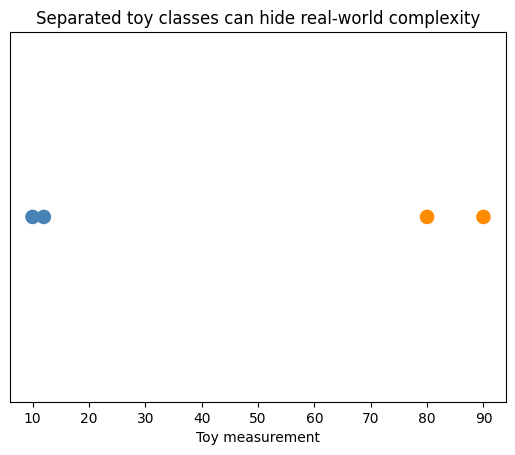

In [6]:
import matplotlib.pyplot as plt
values, labels = [10, 12, 80, 90], ["class 0", "class 0", "class 1", "class 1"]
plt.scatter(values, [0]*len(values), c=["steelblue" if x == "class 0" else "darkorange" for x in labels], s=90)
plt.yticks([])
plt.xlabel("Toy measurement")
plt.title("Separated toy classes can hide real-world complexity")
plt.show()

The figure supports visual intuition only; it is not validation evidence.

## Section H — Debugging and common mistakes

The following code intentionally reaches an invalid-input path but catches the exception, leaving an inspectable message rather than an unhandled notebook error.

In [7]:
def validate_training(rows):
    if not rows:
        raise ValueError("training data must not be empty")

try:
    validate_training([])
except ValueError as error:
    print("Caught expected data error:", error)
print("Fix: verify ingestion and label counts before fitting.")

Caught expected data error: training data must not be empty
Fix: verify ingestion and label counts before fitting.


Reject malformed input explicitly; never substitute a success-shaped prediction or silently perform an operational action.

## Section I — Exercises

1. Add finite-number checks. 2. Test equal-distance centroids and document ambiguity. 3. Identify a time-series leakage example and design a safer split.

Attempt these before using the separate `07_Exercise_Solutions.ipynb`.

## Section J — Summary and knowledge check

Validate inputs and fitted state, do not invent defaults, and do not call a training score a generalization estimate. Which failure should disable a recommendation service?

**Review:** What are the input, output, assumptions, failure mode, and safe fallback? Continue with the full theory notes and then AI problem formulation: goals, state, actions, constraints, costs, and success criteria.